# 01 - Data foundations: genotype arrays, QC, and what a "genetic grouping" can mean

This notebook is the first step of the *balkan-study* walkthrough. It explains the
raw material of the whole project: autosomal SNP array genotypes from 70
western Balkan individuals (Kovacevic et al. 2014, GEO GSE59032) plus a
present-day reference panel decoded from the Allen Ancient DNA Resource
(AADR v66.p1).

By the end you should be able to answer:

1. What is stored in a genotype dataset, and what does the 0/1/2 dosage mean?
2. What do standard QC metrics (call rate, MAF, HWE, LD, relatedness) tell us?
3. Why is the raw genotype matrix a bad input for k-means?

The actual file-format archaeology (GenomeStudio tables, AADR `tgeno`) lives
in `scripts/01_geo_to_plink.py`, `scripts/02_aadr_to_plink.py` and
`scripts/03_merge_modern.py`; this notebook works with their outputs.

In [1]:
from pathlib import Path
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
import balkan_study_io as pio

FIG = ROOT / "results" / "figures"
TAB = ROOT / "results" / "tables"
NB = ROOT / "data" / "processed" / "nb01"
for d in (FIG, TAB, NB):
    d.mkdir(parents=True, exist_ok=True)

PLINK2 = "plink2"
MERGED = ROOT / "data" / "processed" / "modern_merged"
print("project root:", ROOT)
print("plink2:", subprocess.run([PLINK2, "--version"], capture_output=True, text=True).stdout.strip().splitlines()[0])

project root: .
plink2: PLINK v2.0.0-a.7.9 64-bit (27 Sep 2026)


## 1. What is in the dataset?

A genotype array measures, for each person, the alleles carried at a fixed set
of positions in the genome. For a biallelic SNP with alleles `A1` and `A2`,
the usual encoding is the **dosage of A1**:

- `2` = A1/A1 (homozygous for allele 1)
- `1` = A1/A2 (heterozygous)
- `0` = A2/A2 (homozygous for allele 2)
- missing = no call

The PLINK `.bed` file stores these as 2-bit codes:
`00 = hom A1`, `01 = missing`, `10 = het`, `11 = hom A2`.
The `.bim` file names the alleles for each SNP, and the `.fam` file lists the
samples. `scripts/balkan_study_io.py` wraps numpy readers/writers for this format.

Our merged dataset contains:

- **70 western Balkan samples** from GEO GSE59032: Bosniac (15),
  Bosnian_Serb (4), Serbian (14), Montenegrin (14), Macedonian (14),
  Kosovar (9).
- **2,816 present-day reference samples** from AADR (Croatian, Bulgarian,
  Greek, Albanian, Romanian, Moldavian, Hungarian, Gagauz, Turkish, and many
  other European, Caucasus and Middle Eastern populations).

The two sources were merged on SNPs shared by both (the GEO array covers
530,659 of the AADR panel's markers; 133,904 shared; 129,269 kept after
orientation and call-rate checks).

In [2]:
meta = pd.read_csv(ROOT / "data" / "metadata" / "modern_merged_samples.tsv", sep="\t")
fam = pio.read_fam(str(MERGED) + ".fam")
bim = pio.read_bim(str(MERGED) + ".bim")
print(f"{len(bim):,} SNPs x {len(fam):,} samples")
print()
counts = meta.groupby(["source", "group"]).size().sort_values(ascending=False)
display(counts.head(30).to_frame("n"))

129,269 SNPs x 2,374 samples



n
source group           
aadr   Spanish      175
       Han          111
       YRI          111
       TSI          108
       CHS          105
       CHB          103
       JPT          103
       CEU           99
       FIN           89
       GBR           79
       Russian       76
       French        66
       Palestinian   49
       Turkish       48
       IBS           45
       Druze         44
       Iranian       39
       Basque        35
       Adygei        35
       Japanese      33
       Papuan        32
       Sardinian     31
       BedouinA      25
       Biaka         25
       Georgian      24
       Mayan         23
       Hungarian     22
       BedouinB      21
       Greek         19
       Ossetian      18

The `group` column carries the self-identified / population label, and
`source` tells us whether a sample is one of the paper's 70 Balkan samples
(`geo`) or a reference sample (`aadr`). Everything about "nations" in this
project lives in that column - it is social metadata, not something genetics
defines.

## 2. Missingness (call rate)

Arrays occasionally fail to genotype a SNP for a sample; the proportion of
missing calls is the complement of the **call rate**. Samples with a high
missing rate often failed technically; SNPs with high missingness are often
poorly designed probes. Common thresholds: remove samples >2-5% missing and
SNPs >2-5% missing.

In [3]:
def run(cmd):
    print("$", " ".join(str(c) for c in cmd))
    result = subprocess.run([str(c) for c in cmd], cwd=ROOT, capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stdout[-2000:])
        print(result.stderr[-2000:])
        result.check_returncode()
    return result.stdout

run([PLINK2, "--bfile", MERGED, "--missing", "--freq", "--out", NB / "qc"])
smiss = pd.read_csv(NB / "qc.smiss", sep=r"\s+").rename(columns={"IID": "iid"})
vmiss = pd.read_csv(NB / "qc.vmiss", sep=r"\s+")
afreq = pd.read_csv(NB / "qc.afreq", sep=r"\s+")
print("samples:", len(smiss), " variants:", len(vmiss))
print("sample missing: mean %.4f max %.4f" % (smiss["F_MISS"].mean(), smiss["F_MISS"].max()))
print("variant missing: mean %.4f max %.4f" % (vmiss["F_MISS"].mean(), vmiss["F_MISS"].max()))

$ plink2 --bfile ./data/processed/modern_merged --missing --freq --out ./data/processed/nb01/qc


samples: 2374  variants: 129269
sample missing: mean 0.0075 max 0.0810
variant missing: mean 0.0082 max 0.5312


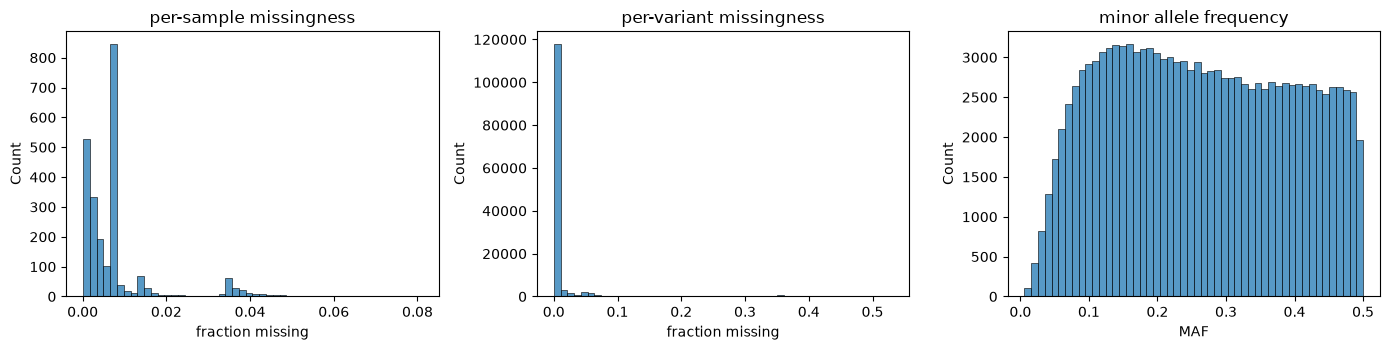

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
sns.histplot(smiss["F_MISS"], bins=50, ax=axes[0]); axes[0].set_title("per-sample missingness")
axes[0].set_xlabel("fraction missing")
sns.histplot(vmiss["F_MISS"], bins=50, ax=axes[1]); axes[1].set_title("per-variant missingness")
axes[1].set_xlabel("fraction missing")
maf = afreq[["ALT_FREQS"]].rename(columns={"ALT_FREQS": "alt_freq"})
maf["maf"] = np.minimum(maf["alt_freq"], 1 - maf["alt_freq"])
sns.histplot(maf["maf"], bins=50, ax=axes[2]); axes[2].set_title("minor allele frequency")
axes[2].set_xlabel("MAF")
fig.tight_layout(); fig.savefig(FIG / "nb01_missing_maf.png", dpi=130); plt.show()

## 3. Minor allele frequency (MAF)

Allele frequencies vary along the genome. Rare variants (MAF near 0) carry
little information for population structure, are noisier, and are more
sensitive to genotyping error; most structure analyses keep MAF >= 1-5%.
The panel is enriched for common variants, as expected for an array plus a
curated ancient-DNA site list.

## 4. Linkage disequilibrium (LD) and why we prune

Nearby SNPs are often correlated because they are inherited together on the
same haplotype. High LD violates the independence assumptions of most
clustering and PCA-style methods, and it silently *weights* some genomic
regions more than others. The standard fix is **LD pruning**: greedily remove
SNPs so that no pair within a sliding window has r^2 above a threshold.

The paper used `--indep-pairwise 200 25 0.4` (200-SNP windows, step 25,
r^2 > 0.4 removed); we use the same here.

In [5]:
run([PLINK2, "--bfile", MERGED, "--autosome", "--maf", "0.01", "--geno", "0.05", "--hwe", "1e-6", "midp",
     "--indep-pairwise", "200", "25", "0.4", "--out", NB / "pruned"])
prune_in = [line.strip() for line in open(NB / "pruned.prune.in")]
print(f"SNPs after filters + LD pruning: {len(prune_in):,}")
run([PLINK2, "--bfile", MERGED, "--autosome", "--maf", "0.01", "--geno", "0.05", "--hwe", "1e-6", "midp",
     "--extract", NB / "pruned.prune.in", "--make-bed", "--out", NB / "analysis"])
print("wrote analysis dataset:", NB / "analysis.bed")

$ plink2 --bfile ./data/processed/modern_merged --autosome --maf 0.01 --geno 0.05 --hwe 1e-6 midp --indep-pairwise 200 25 0.4 --out ./data/processed/nb01/pruned


SNPs after filters + LD pruning: 72,552
$ plink2 --bfile ./data/processed/modern_merged --autosome --maf 0.01 --geno 0.05 --hwe 1e-6 midp --extract ./data/processed/nb01/pruned.prune.in --make-bed --out ./data/processed/nb01/analysis


wrote analysis dataset: ./data/processed/nb01/analysis.bed


## 5. Relatedness

Population structure methods assume (roughly) unrelated samples. KING robust
kinship estimates relatedness using only SNPs where two individuals share at
least one rare allele, which makes it robust to population structure.
In PLINK 2's output, monozygotic twins / duplicate samples score about 0.5,
first-degree relatives about 0.25, and the usual interpretation bins are:

| kinship | relationship |
|---|---|
| > 0.354 | duplicate / monozygotic twin |
| 0.177 - 0.354 | first degree (parent-child, siblings) |
| 0.0884 - 0.177 | second degree |
| 0.0442 - 0.0884 | third degree |

One subtlety: AADR lists the same person once per source assay, e.g.
`NA12878.DG` (sequenced) and `NA12878.HO` (array). `scripts/03_merge_modern.py`
already collapsed those technical duplicates by keeping the copy with the
fewest missing calls, so the remaining close pairs should be genuine
relatives inside the reference populations.

$ plink2 --bfile ./data/processed/nb01/analysis --make-king-table --king-table-filter 0.0442 --out ./data/processed/nb01/king


pairs at 3rd degree or closer: 562
KINSHIP
3rd    451
2nd     25
1st      0
dup     86
dtype: int64


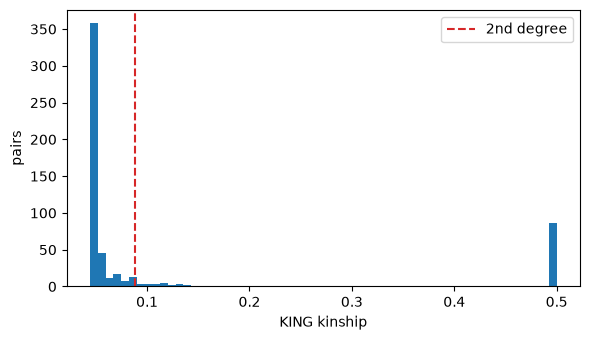

In [6]:
run([PLINK2, "--bfile", NB / "analysis", "--make-king-table", "--king-table-filter", "0.0442", "--out", NB / "king"])
kin = pd.read_csv(NB / "king.kin0", sep=r"\s+")
print("pairs at 3rd degree or closer:", len(kin))
bins = pd.cut(kin["KINSHIP"], [0.0442, 0.0884, 0.177, 0.354, 1.0],
              labels=["3rd", "2nd", "1st", "dup"], include_lowest=True)
print(kin.groupby(bins, observed=False).size())
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(kin["KINSHIP"], bins=60)
ax.axvline(0.0884, color="tab:red", ls="--", label="2nd degree")
ax.set_xlabel("KING kinship"); ax.set_ylabel("pairs"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "nb01_kinship.png", dpi=130); plt.show()

## 6. Heterozygosity

The inbreeding coefficient F compares observed to expected homozygosity. It is
a useful QC signal (e.g. sample contamination or inbreeding) but it is also
strongly affected by ancestry: a sample from a population with a different
allele-frequency profile will look like an outlier. So always inspect F
**within** a homogeneous group.

$ plink2 --bfile ./data/processed/nb01/analysis --het --out ./data/processed/nb01/het


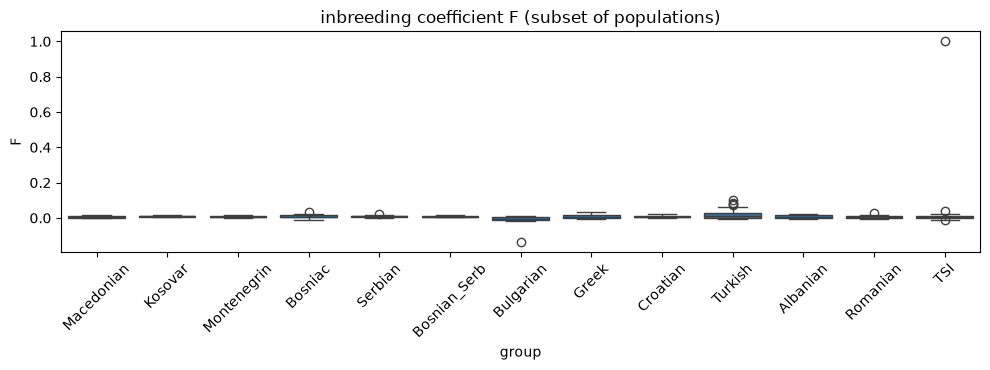

In [7]:
run([PLINK2, "--bfile", NB / "analysis", "--het", "--out", NB / "het"])
het = pd.read_csv(NB / "het.het", sep=r"\s+").rename(columns={"IID": "iid"}).merge(meta, on="iid", how="left")
balkan = {"Bosniac", "Bosnian_Serb", "Serbian", "Montenegrin", "Macedonian", "Kosovar"}
keep = het[het["group"].isin(balkan | {"Croatian", "Bulgarian", "Greek", "Albanian", "Romanian", "TSI", "Turkish"})]
fig, ax = plt.subplots(figsize=(10, 3.8))
sns.boxplot(data=keep, x="group", y="F", ax=ax)
ax.tick_params(axis="x", rotation=45); ax.set_title("inbreeding coefficient F (subset of populations)")
fig.tight_layout(); fig.savefig(FIG / "nb01_het.png", dpi=130); plt.show()

## 7. Your first look at the genotype matrix

Let us actually load a small piece of the binary matrix and see the 0/1/2
structure. We read the full analysis dataset (it is small enough at this
point), then look at a few SNPs and the per-SNP allele frequency spectrum.

**Key point:** each row is a SNP, each column a person. There is no obvious
"cluster" label in the matrix itself - structure must be inferred, and every
inference method makes assumptions.

In [8]:
analysis_fam = pio.read_fam(str(NB / "analysis") + ".fam")
analysis_bim = pio.read_bim(str(NB / "analysis") + ".bim")
G = pio.read_bed_dosage(str(NB / "analysis") + ".bed", len(analysis_fam), len(analysis_bim))
print("matrix shape (SNPs x individuals):", G.shape)
print("first 8 SNPs, first 12 samples:")
print(pd.DataFrame(G[:8, :12], index=[r["rsid"] for r in analysis_bim[:8]],
                  columns=[s["iid"] for s in analysis_fam[:12]]).to_string())

matrix shape (SNPs x individuals): (72552, 2374)
first 8 SNPs, first 12 samples:
            Macedonian10  Macedonian12  Macedonian14  Macedonian17b-d  Macedonian19  Macedonian2  Macedonian20  Macedonian21  Macedonian22  Macedonian3  Macedonian6  Macedonian7
rs3094315              0             2            -1                1             2            1             2             2             1            2            1            2
rs9442372              2             0             1                0             2            1             1             2             1            2            2            1
rs4970405              0             0             1                0             0            0             0             0             0            1            2            1
rs11807848             0             1             2                2             0            0             1             0             1            1            2            2
rs3813199              0     

## Exercises

1. How many SNPs and samples survive each QC filter (MAF, geno, HWE, pruning)?
   Which filter removes the most?
2. Are there any samples with F_MISS > 5%? Which populations are they from,
   and would dropping them change the Balkan sample sizes much?
3. Why does the heterozygosity plot show some populations with systematically
   higher F? (Hint: it is not inbreeding.)
4. Try removing LD pruning: how many SNPs remain, and how much memory does
   the matrix take?

Next: `02_pca.ipynb` builds intuition for PCA with simulations, then applies
it to this dataset.